# Detecting photovoltaic installations with a multi-task LSTM

**AIL × Neural Wave · reproducible local baseline**

This notebook implements all three required tasks: PV presence, initial commissioning date, and initial nominal capacity in kWp. It trains on the 40 labelled development customers, measures generalization with customer-level cross-validation, fits a final model, and exports a complete offline submission.

The attached repository suggests a graph-attention approach. The implementation here follows your requested **LSTM** approach. Consumption and derived calendar features are the only model inputs. Customer IDs serve as join keys, never features. No external data or LLM is used by this pipeline.

**Latest results:** see the improvement study at the end of this notebook. The original baseline below is preserved for comparison.

**Scope:** a trained baseline, not a claim of competition-winning performance. The optional extension detector is omitted; its required CSV is written with its header only. Battery detection is outside the challenge.

## Run locally

Select the `.venv` Python kernel in Jupyter or VS Code, then **Run All**. If setting up a new machine, run the optional install cell below first. The data must remain on your machine. CPU is the default for portability and repeatability. Training takes several minutes.


In [1]:
# Optional setup in a fresh kernel (uncomment if dependencies are missing):
# %pip install torch numpy pandas scikit-learn matplotlib nbformat nbclient ipykernel


## Configuration

The epoch count, learning rate, losses, architecture, and presence threshold are fixed before cross-validation. The held-out customer in each fold is excluded from training and learned normalization. Cross-validation predictions are for evaluation only; they are not submission predictions.

The 7.4 GB unlabelled file is optional and is not needed for this supervised baseline. It must never be assigned negative labels merely because labels are absent.


In [2]:
from pathlib import Path
import os

# Run from the notebook folder, or from lstm_submission/.
ROOT = Path.cwd()
if not (ROOT / "AIL_data_for_neural_wave_v1.1").exists() and (ROOT.parent / "AIL_data_for_neural_wave_v1.1").exists():
    ROOT = ROOT.parent
DATA = ROOT / "AIL_data_for_neural_wave_v1.1" / "challenge_set"
TRAIN_CSV = DATA / "energy_consumption_dev.csv"
LABEL_CSV = DATA / "pv_labels_dev.csv"
SUBMISSION = ROOT / "lstm_submission"
ARTIFACTS = SUBMISSION / "artifacts"
ARTIFACTS.mkdir(parents=True, exist_ok=True)

SEED = 42
EPOCHS = int(os.environ.get("PV_LSTM_EPOCHS", "30"))
FOLDS = 5
HIDDEN_SIZE = 24
THRESHOLD = 0.5
assert TRAIN_CSV.exists() and LABEL_CSV.exists(), "Update DATA to the challenge_set folder."
assert EPOCHS > 0
print(f"Configuration: {FOLDS} customer folds; {EPOCHS} epochs per fit; CPU")


Configuration: 5 customer folds; 30 epochs per fit; CPU


## Imports and reproducibility

Imports and deterministic seeding. No data is fetched from the network.

In [3]:
"""Local multi-task LSTM baseline for the AIL PV challenge.

Only consumption and calendar information are used. Customer IDs are join keys,
never model inputs. All learned preprocessing is fitted on training customers.
"""
from __future__ import annotations

import copy
import csv
import json
import random
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold

COLUMNS = ['customer_id', 'energy_consumption_kwh', 'timestamp_local', 'timestamp_epoch']
OUTPUT_COLUMNS = ['customer_id', 'pv_installed', 'pv_installation_date', 'pv_capacity_kwp']
EXT_COLUMNS = ['customer_id', 'extension_date', 'pv_capacity_after_extension_kwp']
TZ = 'Europe/Zurich'


def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(min(4, torch.get_num_threads()))
    torch.use_deterministic_algorithms(True)


def delimiter(path):
    with open(path, encoding='utf-8-sig', newline='') as f:
        return csv.Sniffer().sniff(f.read(4096), delimiters=';,\t').delimiter


@dataclass
class CustomerSeries:
    customer_id: str
    dates: pd.DatetimeIndex
    x: np.ndarray
    scale: float
    quality: np.ndarray

## Streaming ingestion, DST and daily feature engineering

A raw 15-minute observation is **energy in kWh**; multiplying by 4 converts it to average kW. We stream the CSV and aggregate by customer, local date, and hour, using epoch timestamps as the authority. Spring and autumn days retain their 92 and 100 intervals. Repeated autumn hours are averaged, not discarded. Invalid/negative energy values are masked and counted; duplicate ID/epoch readings are rejected even across chunks.

Each daily vector has **57 features**: 24 hourly load shapes, 24 coverage indicators, daily energy, day/night contrast, four cyclical calendar features, elapsed years, daily coverage, and log consumption scale. Unobserved hours use the customer's median; coverage exposes the imputation. Missing days remain in the sequence. Each customer's scale is inferred from its own complete observed history because this is a retrospective task.

In [4]:
def load_series(path, chunksize=250_000):
    """Stream raw measurements into daily hourly profiles without loading the CSV.

    Epoch timestamps determine local clock time. Each observation is interval
    ENERGY: multiply by four for average kW, never by 96. Repeated autumn hours
    are averaged; daily energy and expected coverage retain their 25-hour day.
    Duplicate customer/epoch readings are rejected, including across chunks.
    A compact timestamp bitmap makes validation practical for large files.
    """
    parts, seen, all_ids = [], {}, set()
    invalid_values = 0
    reader = pd.read_csv(path, sep=delimiter(path), encoding='utf-8-sig',
                         dtype={'customer_id': 'string'}, chunksize=chunksize)
    for chunk in reader:
        missing = set(COLUMNS) - set(chunk.columns)
        if missing:
            raise ValueError(f'Missing input columns: {sorted(missing)}')
        if chunk.customer_id.isna().any() or chunk.customer_id.str.len().eq(0).any():
            raise ValueError('Each measurement requires a nonempty customer_id.')
        all_ids.update(chunk.customer_id.astype(str))
        epoch = pd.to_numeric(chunk.timestamp_epoch, errors='raise').to_numpy(float)
        if not np.isfinite(epoch).all() or np.any(epoch % 900 != 0):
            raise ValueError('timestamp_epoch must be integral Unix seconds on a 15-minute grid.')
        steps = epoch.astype(np.int64) // 900
        # Detect arbitrary-order duplicates without retaining millions of Python ints.
        for cid, indices in chunk.groupby('customer_id', sort=False).indices.items():
            values = np.sort(steps[indices])
            if np.any(np.diff(values) == 0):
                raise ValueError('Duplicate customer_id/timestamp_epoch readings.')
            buckets = values // 64
            boundaries = np.r_[0, np.flatnonzero(np.diff(buckets)) + 1, len(values)]
            for lo, hi in zip(boundaries[:-1], boundaries[1:]):
                bits = np.left_shift(np.uint64(1), (values[lo:hi] % 64).astype(np.uint64))
                mask = int(np.bitwise_or.reduce(bits))
                key = (str(cid), int(buckets[lo]))
                old = seen.get(key, 0)
                if old & mask:
                    raise ValueError('Duplicate readings across input chunks.')
                seen[key] = old | mask
        local = pd.to_datetime(epoch, unit='s', utc=True).tz_convert(TZ)
        # Local clock fields are derived from the unambiguous epoch, including DST.
        dates = local.tz_localize(None).normalize()
        kwh = pd.to_numeric(chunk.energy_consumption_kwh, errors='coerce').to_numpy(float)
        valid = np.isfinite(kwh) & (kwh >= 0)
        invalid_values += int((~valid).sum())
        frame = pd.DataFrame({'customer_id': chunk.customer_id.to_numpy(),
                              'date': dates, 'hour': local.hour,
                              'kwh': np.where(valid, kwh, np.nan)})
        parts.append(frame.groupby(['customer_id', 'date', 'hour'], sort=False)
                     .kwh.agg(['sum', 'count']))
    if not parts:
        raise ValueError('The input contains no measurements.')
    hourly = pd.concat(parts).groupby(level=[0, 1, 2], sort=True).sum()
    series = []
    for cid in sorted(all_ids):
        table = hourly.xs(cid, level=0)
        dates = pd.date_range(table.index.get_level_values('date').min(),
                              table.index.get_level_values('date').max(), freq='D')
        index = pd.MultiIndex.from_product([dates, range(24)], names=['date', 'hour'])
        table = table.reindex(index, fill_value=0)
        counts = table['count'].to_numpy(float).reshape(-1, 24)
        energy = table['sum'].to_numpy(float).reshape(-1, 24)
        hourly_kw = np.divide(4 * energy, counts, out=np.full_like(energy, np.nan), where=counts > 0)
        # 92/100 intervals at spring/autumn DST, 96 otherwise.
        midnights = pd.date_range(dates[0], dates[-1] + pd.Timedelta(days=1), freq='D', tz=TZ)
        expected_day = np.diff(midnights.as_unit('ns').asi8) / (900 * 1e9)
        expected = np.full_like(counts, 4.)
        expected[:, 2] = expected_day - 92
        coverage = np.divide(counts, expected, out=np.ones_like(counts), where=expected > 0)
        coverage = np.clip(coverage, 0, 1)
        quality = np.clip(counts.sum(axis=1) / expected_day, 0, 1)
        observed = hourly_kw[np.isfinite(hourly_kw)]
        scale = max(float(np.median(observed)) if len(observed) else 0., 0.01)
        # Per-customer robust scale is computed from that customer's observed input,
        # which is permitted for this retrospective (whole-history) task.
        filled = np.where(np.isfinite(hourly_kw), hourly_kw, scale)
        shape = np.log1p(np.clip(filled / scale, 0, 1e4))
        daily_energy = energy.sum(axis=1)
        energy_feature = np.log1p(daily_energy / (24 * scale))[:, None]
        daytime = filled[:, 9:16].mean(axis=1)
        nighttime = filled[:, [0, 1, 3, 4, 5, 21, 22, 23]].mean(axis=1)
        contrast = np.clip((nighttime - daytime) / scale, -20, 20)[:, None]
        doy = dates.dayofyear.to_numpy() / 365.25 * (2 * np.pi)
        dow = dates.dayofweek.to_numpy() / 7 * (2 * np.pi)
        calendar = np.column_stack([np.sin(doy), np.cos(doy), np.sin(dow), np.cos(dow)])
        elapsed = (np.arange(len(dates)) / 365.25)[:, None]
        x = np.column_stack([shape, coverage, energy_feature, contrast, calendar,
                             elapsed, quality, np.full(len(dates), np.log1p(scale))]).astype('float32')
        series.append(CustomerSeries(str(cid), dates, x, scale, quality.astype('float32')))
    return series, {'customers': len(series), 'invalid_energy_readings_masked': invalid_values,
                    'feature_count': series[0].x.shape[1]}


def read_labels(path):
    labels = pd.read_csv(path, sep=delimiter(path), dtype={'customer_id': 'string'},
                         encoding='utf-8-sig')
    if set(OUTPUT_COLUMNS) - set(labels.columns):
        raise ValueError('The label file is missing required columns.')
    if labels.customer_id.isna().any() or labels.customer_id.duplicated().any():
        raise ValueError('Label IDs must be unique and nonempty.')
    boolean = labels.pv_installed.astype(str).str.upper().map({'TRUE': 1, 'FALSE': 0})
    if boolean.isna().any():
        raise ValueError('pv_installed must contain TRUE/FALSE.')
    labels['pv_installed'] = boolean.astype(int)
    labels['pv_installation_date'] = pd.to_datetime(labels.pv_installation_date, errors='coerce')
    labels['pv_capacity_kwp'] = pd.to_numeric(labels.pv_capacity_kwp, errors='coerce')
    pv = labels.pv_installed.eq(1)
    if labels.loc[pv, 'pv_installation_date'].isna().any():
        raise ValueError('Every positive label needs a valid commissioning date.')
    cap = labels.loc[pv, 'pv_capacity_kwp'].to_numpy(float)
    if not np.isfinite(cap).all() or np.any(cap <= 0):
        raise ValueError('Every positive label needs a positive finite capacity.')
    return labels.set_index('customer_id')

## Training-only normalization and customer batches

Fit standardization exclusively on training customers, with equal customer weighting. Pad histories for batching and use packed sequences so padding never enters the recurrent states. One customer is one supervised case: thousands of daily readings do not create thousands of independent customer labels.

Date targets outside observed coverage are censored rather than clipped into false boundary targets. This baseline only predicts dates within observed history, so pre-coverage commissioning requires a different model.

In [5]:
class FeatureScaler:
    def fit(self, series):
        # Give each customer equal weight, even when histories differ in length.
        means = np.stack([s.x.mean(axis=0) for s in series])
        second = np.stack([(s.x ** 2).mean(axis=0) for s in series])
        self.mean = means.mean(axis=0)
        self.std = np.sqrt(np.maximum(second.mean(axis=0) - self.mean ** 2, 1e-4))
        return self

    def transform(self, x):
        return np.clip((x - self.mean) / self.std, -10, 10).astype('float32')


class CustomerDataset(Dataset):
    def __init__(self, series, scaler, labels=None):
        self.series, self.scaler, self.labels = series, scaler, labels

    def __len__(self):
        return len(self.series)

    def __getitem__(self, i):
        s = self.series[i]
        item = {'x': torch.from_numpy(self.scaler.transform(s.x)), 'series': s}
        if self.labels is not None:
            label = self.labels.loc[s.customer_id]
            pv = float(label.pv_installed)
            offset = (label.pv_installation_date - s.dates[0]).days if pv else 0
            # Out-of-coverage dates are censored, not clipped into false targets.
            item.update(pv=pv, date=float(offset), date_valid=bool(pv and 0 <= offset < len(s.dates)),
                        capacity=float(np.log1p(label.pv_capacity_kwp)) if pv else 0.)
        return item


def collate(items):
    lengths = torch.tensor([len(item['x']) for item in items], dtype=torch.long)
    x = pad_sequence([item['x'] for item in items], batch_first=True)
    mask = torch.arange(x.shape[1])[None, :] < lengths[:, None]
    batch = {'x': x, 'lengths': lengths, 'mask': mask, 'series': [i['series'] for i in items]}
    if 'pv' in items[0]:
        for key in ['pv', 'date', 'date_valid', 'capacity']:
            batch[key] = torch.tensor([i[key] for i in items], dtype=torch.float32)
    return batch

## Multi-task bidirectional LSTM

```text
Daily features → feature projection → bidirectional LSTM
                                      ├─ mean/max pooling → PV probability
                                      ├─ daily state + 7-day change → commissioning-date distribution
                                      ├─ daily state → auxiliary PV-active supervision
                                      └─ pooled + date-local context → log(1 + initial capacity)
```

The complete history is available at inference, so future context is legitimate for retrospective detection. A seven-day soft target supervises commissioning dates. The capacity head uses a 30-day context after candidate commissioning dates alongside the customer representation. Only the **initial** capacity labels supervise this head; extension capacities are never substituted.

Loss = presence BCE + 0.30 × date cross-entropy + 0.60 × capacity Huber + 0.30 × active-state BCE. Negative customers contribute to presence and active-state losses; date and capacity losses are masked. The class weight and initial capacity prior come only from the training fold.

In [6]:
class PVLSTM(nn.Module):
    """Daily recurrent states, customer classification, date localization and kWp.

    Bidirectional context is appropriate because inference observes the complete
    customer history. This model is not an online event detector.
    """
    def __init__(self, input_size, hidden_size=24, dropout=0.20):
        super().__init__()
        self.config = dict(input_size=input_size, hidden_size=hidden_size, dropout=dropout)
        self.encoder = nn.Sequential(nn.Linear(input_size, hidden_size), nn.Tanh())
        self.lstm = nn.LSTM(hidden_size, hidden_size, batch_first=True, bidirectional=True)
        width = 2 * hidden_size
        self.dropout = nn.Dropout(dropout)
        self.presence = nn.Sequential(nn.Linear(2 * width, hidden_size), nn.ReLU(),
                                      nn.Dropout(dropout), nn.Linear(hidden_size, 1))
        self.date_head = nn.Sequential(nn.Linear(2 * width, hidden_size), nn.Tanh(), nn.Linear(hidden_size, 1))
        self.active_head = nn.Linear(width, 1)
        self.capacity_head = nn.Sequential(nn.Linear(3 * width, hidden_size), nn.ReLU(), nn.Linear(hidden_size, 1))

    def forward(self, x, lengths, mask):
        z = self.encoder(x)
        packed = pack_padded_sequence(z, lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed, _ = self.lstm(packed)
        h, _ = pad_packed_sequence(packed, batch_first=True, total_length=x.shape[1])
        h = self.dropout(h)
        mean = (h * mask[..., None]).sum(1) / lengths.to(h.device)[:, None]
        maximum = h.masked_fill(~mask[..., None], -1e4).max(1).values
        pooled = torch.cat([mean, maximum], dim=-1)
        previous = torch.cat([h[:, :1].expand(-1, 7, -1), h], dim=1)[:, :h.shape[1]]
        logits = self.date_head(torch.cat([h, h - previous], dim=-1)).squeeze(-1)
        logits = logits.masked_fill(~mask, -1e4)
        # A local window after each candidate date helps estimate initial capacity,
        # instead of forcing the regression to describe the final extended system.
        after = nn.functional.avg_pool1d(nn.functional.pad(h.transpose(1, 2), (0, 29)),
                                         kernel_size=30, stride=1).transpose(1, 2)
        event = (logits.softmax(1)[..., None] * after).sum(1)
        capacity = self.capacity_head(torch.cat([pooled, event], dim=-1)).squeeze(-1)
        return {'presence': self.presence(pooled).squeeze(-1), 'date_logits': logits,
                'active_logits': self.active_head(h).squeeze(-1), 'log_capacity': capacity}


def multitask_loss(out, batch, positive_weight):
    presence = nn.functional.binary_cross_entropy_with_logits(
        out['presence'], batch['pv'], pos_weight=positive_weight)
    time = torch.arange(batch['x'].shape[1], device=batch['x'].device)[None, :]
    known_date = batch['date_valid'].bool()
    zero = out['presence'].sum() * 0
    if known_date.any():
        # A seven-day Gaussian target tolerates registration/noisy daily signals.
        target = torch.exp(-0.5 * ((time - batch['date'][:, None]) / 7.) ** 2) * batch['mask']
        target = target / target.sum(1, keepdim=True).clamp_min(1e-12)
        date_loss = -(target * out['date_logits'].log_softmax(1)).sum(1)[known_date].mean()
    else:
        date_loss = zero
    positives = batch['pv'].bool()
    capacity = nn.functional.smooth_l1_loss(out['log_capacity'][positives],
                                           batch['capacity'][positives]) if positives.any() else zero
    active_target = (time >= batch['date'][:, None]).float() * batch['pv'][:, None]
    active_loss = nn.functional.binary_cross_entropy_with_logits(out['active_logits'], active_target, reduction='none')
    # Normalize per customer, so four years of readings is still ONE label.
    active_loss = ((active_loss * batch['mask']).sum(1) / batch['lengths'].to(time.device)).mean()
    return presence + 0.30 * date_loss + 0.60 * capacity + 0.30 * active_loss

## Fit, predict, and exact challenge metrics

Train with AdamW, dropout, weight decay, and gradient clipping. Prediction uses a local posterior mode for dates rather than averaging peaks in different years. A fixed 0.5 threshold determines PV presence. Positive capacities are decoded from log space.

The main score is implemented as **F1 × (70 + 15D + 15P)**. Date and capacity components are averaged over true positives; invalid values score zero. Date error reaches zero credit at 30 days and relative capacity error at 50%. Both F1 and the full challenge score matter.

In [7]:
def fit_model(series, labels, epochs=60, seed=42, hidden_size=24, batch_size=8, device='cpu', verbose=False):
    seed_everything(seed)
    scaler = FeatureScaler().fit(series)
    dataset = CustomerDataset(series, scaler, labels)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True, collate_fn=collate,
                        generator=torch.Generator().manual_seed(seed))
    model = PVLSTM(series[0].x.shape[1], hidden_size).to(device)
    y = labels.loc[[s.customer_id for s in series], 'pv_installed'].to_numpy()
    positive_weight = torch.tensor((len(y) - y.sum()) / max(y.sum(), 1), device=device)
    # Capacity bias starts at a train-only geometric prior rather than near zero kWp.
    positive_cap = labels.loc[[s.customer_id for s in series], :].query('pv_installed == 1').pv_capacity_kwp
    if len(positive_cap):
        nn.init.constant_(model.capacity_head[-1].bias, float(np.log1p(positive_cap).mean()))
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-3)
    history = []
    for epoch in range(epochs):
        model.train()
        losses = []
        for batch in loader:
            batch = {k: v.to(device) if torch.is_tensor(v) and k != 'lengths' else v for k, v in batch.items()}
            optimizer.zero_grad(set_to_none=True)
            loss = multitask_loss(model(batch['x'], batch['lengths'], batch['mask']), batch, positive_weight)
            if not torch.isfinite(loss):
                raise FloatingPointError('Non-finite training loss.')
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))
        history.append(float(np.mean(losses)))
        if verbose and (epoch == 0 or (epoch + 1) % 10 == 0):
            print(f'Epoch {epoch + 1}/{epochs}: loss={history[-1]:.4f}', flush=True)
    return model.cpu(), scaler, history


@torch.no_grad()
def predict(model, scaler, series, threshold=0.5):
    model.eval()
    rows = []
    loader = DataLoader(CustomerDataset(series, scaler), batch_size=8, collate_fn=collate)
    for batch in loader:
        out = model(batch['x'], batch['lengths'], batch['mask'])
        probabilities = out['presence'].sigmoid().numpy()
        date_prob = out['date_logits'].softmax(1).numpy()
        capacities = np.expm1(np.clip(out['log_capacity'].numpy(), np.log1p(0.01), np.log1p(1e5)))
        for i, s in enumerate(batch['series']):
            # Maximum posterior 30-day neighbourhood matches the challenge's date
            # tolerance better than averaging unrelated peaks across years.
            p = date_prob[i, :len(s.dates)]
            window = np.convolve(p, np.ones(min(15, len(p))), mode='same')
            offset = int(window.argmax())
            lo, hi = max(0, offset - 7), min(len(p), offset + 8)
            local = p[lo:hi]
            offset = int(round(np.dot(np.arange(lo, hi), local) / max(local.sum(), 1e-12)))
            installed = bool(probabilities[i] >= threshold)
            rows.append({'customer_id': s.customer_id, 'pv_installed': installed,
                         'pv_installation_date': s.dates[offset].strftime('%Y-%m-%d') if installed else '',
                         'pv_capacity_kwp': float(capacities[i]) if installed else np.nan,
                         'pv_probability': float(probabilities[i])})
    return pd.DataFrame(rows)


def challenge_metrics(labels, predictions):
    pred = predictions.set_index('customer_id').reindex(labels.index)
    if pred.pv_installed.isna().any():
        raise ValueError('Every labelled customer requires exactly one prediction.')
    y = labels.pv_installed.to_numpy(int)
    yp = pred.pv_installed.astype(int).to_numpy()
    true_positive = (y == 1) & (yp == 1)
    dates = pd.to_datetime(pred.pv_installation_date, errors='coerce')
    errors = (dates - labels.pv_installation_date).dt.days.abs().to_numpy(float)
    cap = pd.to_numeric(pred.pv_capacity_kwp, errors='coerce').to_numpy(float)
    truth = labels.pv_capacity_kwp.to_numpy(float)
    date_scores = np.where(np.isfinite(errors), np.maximum(0, 1 - errors / 30), 0.)
    ape = np.abs(cap - truth) / truth
    cap_scores = np.where(np.isfinite(cap) & (cap > 0) & np.isfinite(ape), np.maximum(0, 1 - ape / .5), 0.)
    f1 = f1_score(y, yp, zero_division=0)
    d = float(date_scores[true_positive].mean()) if true_positive.any() else 0.
    p = float(cap_scores[true_positive].mean()) if true_positive.any() else 0.
    return {'F1': float(f1), 'precision': float(precision_score(y, yp, zero_division=0)),
            'recall': float(recall_score(y, yp, zero_division=0)), 'D': d, 'P': p,
            'main_score': float(f1 * (70 + 15 * d + 15 * p)),
            'true_positives': int(true_positive.sum()),
            'date_MAE_days_on_true_positives': float(errors[true_positive].mean()) if true_positive.any() else None,
            'capacity_MAPE_on_true_positives': float(ape[true_positive].mean()) if true_positive.any() else None}


def cross_validate(series, labels, folds=5, epochs=60, seed=42, hidden_size=24):
    ids = [s.customer_id for s in series]
    if set(ids) != set(labels.index):
        raise ValueError('Development labels and consumption customers must match exactly.')
    y = labels.loc[ids].pv_installed.to_numpy(int)
    if min(np.bincount(y, minlength=2)) < folds:
        raise ValueError('Each class needs at least one customer per fold.')
    splitter = StratifiedKFold(n_splits=folds, shuffle=True, random_state=seed)
    oof, fold_metrics = [], []
    for fold, (train, valid) in enumerate(splitter.split(ids, y), 1):
        train_series, valid_series = [series[i] for i in train], [series[i] for i in valid]
        # Held-out customer labels never enter fitting, normalization, stopping,
        # or threshold selection. Epoch count and threshold are fixed a priori.
        train_labels = labels.loc[[s.customer_id for s in train_series]]
        model, scaler, _ = fit_model(train_series, train_labels, epochs, seed + fold, hidden_size)
        predictions = predict(model, scaler, valid_series)
        predictions['fold'] = fold
        metrics = challenge_metrics(labels.loc[[s.customer_id for s in valid_series]], predictions)
        fold_metrics.append({'fold': fold, **metrics})
        oof.append(predictions)
        print(f'Fold {fold}/{folds}: F1={metrics["F1"]:.3f}, main score={metrics["main_score"]:.2f}', flush=True)
    return pd.concat(oof, ignore_index=True), pd.DataFrame(fold_metrics)

## Portable artifacts and submission formatting

Save weights, architecture, normalization, and threshold together. Reload on CPU with `weights_only=True`. The notebook exports the same function definitions to a support module used by the CLI.

The PDF's normative §4.1 explicitly requires **semicolon-separated UTF-8** files, despite comma-separated examples elsewhere. The exporter follows §4.1, preserves string IDs and leading zeros, and leaves date/capacity blank when PV is FALSE. An empty extension file is valid when the optional task is omitted.

In [8]:
def save_artifact(model, scaler, path, threshold=0.5, metadata=None):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save({'format_version': 1, 'config': model.config, 'state_dict': model.state_dict(),
                'mean': torch.tensor(scaler.mean), 'std': torch.tensor(scaler.std),
                'threshold': float(threshold), 'metadata': metadata or {}}, path)


def load_artifact(path):
    artifact = torch.load(path, map_location='cpu', weights_only=True)
    if artifact['format_version'] != 1:
        raise ValueError('Unsupported model artifact version.')
    model = PVLSTM(**artifact['config'])
    model.load_state_dict(artifact['state_dict'])
    scaler = FeatureScaler()
    scaler.mean, scaler.std = artifact['mean'].numpy(), artifact['std'].numpy()
    return model.eval(), scaler, artifact['threshold']


def write_outputs(predictions, output_dir='.'):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    if predictions.customer_id.duplicated().any():
        raise ValueError('Predictions must have exactly one row per customer.')
    main = predictions[OUTPUT_COLUMNS].copy()
    positive = main.pv_installed.astype(bool)
    if pd.to_datetime(main.loc[positive, 'pv_installation_date'], errors='coerce').isna().any():
        raise ValueError('PV-positive predictions require valid dates.')
    cap = pd.to_numeric(main.loc[positive, 'pv_capacity_kwp'], errors='coerce').to_numpy(float)
    if not np.isfinite(cap).all() or np.any(cap <= 0):
        raise ValueError('PV-positive predictions require positive finite capacities.')
    main['pv_installed'] = np.where(positive, 'TRUE', 'FALSE')
    main.loc[~positive, ['pv_installation_date', 'pv_capacity_kwp']] = ['', np.nan]
    main.to_csv(output_dir / 'predictions.csv', sep=';', index=False, encoding='utf-8',
                na_rep='', float_format='%.6f')
    # Optional extension detection is deliberately unsupported: one development
    # extension cannot validate a general extension estimator.
    pd.DataFrame(columns=EXT_COLUMNS).to_csv(output_dir / 'pv_extensions_predictions.csv',
                                             sep=';', index=False, encoding='utf-8')
    return output_dir / 'predictions.csv', output_dir / 'pv_extensions_predictions.csv'

## Load and validate development data

Only aggregate information is displayed. No raw customer profiles or label rows are included in notebook outputs.

In [9]:
series, ingestion_summary = load_series(TRAIN_CSV)
labels = read_labels(LABEL_CSV)
assert {s.customer_id for s in series} == set(labels.index)
summary = {
    **ingestion_summary,
    "PV customers": int(labels.pv_installed.sum()),
    "non-PV customers": int((1 - labels.pv_installed).sum()),
    "shortest_history_days": min(len(s.dates) for s in series),
    "longest_history_days": max(len(s.dates) for s in series),
}
print(json.dumps(summary, indent=2))
censored = sum(bool(labels.loc[s.customer_id, "pv_installed"]) and not
               (s.dates[0] <= labels.loc[s.customer_id, "pv_installation_date"] <= s.dates[-1])
               for s in series)
print("PV dates outside observed coverage:", censored)


{
  "customers": 40,
  "invalid_energy_readings_masked": 3,
  "feature_count": 57,
  "PV customers": 22,
  "non-PV customers": 18,
  "shortest_history_days": 202,
  "longest_history_days": 1461
}
PV dates outside observed coverage: 0


## Evaluate on unseen customers

Five stratified folds produce one out-of-fold prediction per customer. Folds use disjoint IDs. Every fold starts from fresh weights and fits its own feature scaler and capacity prior. Fixed epochs avoid using held-out labels for early stopping. Do not tune this notebook repeatedly against these same scores and present the resulting score as unbiased.

A prevalence-only reference predicts PV for everyone and reports its classification F1; it is a useful check because F1 rewards recall and the dataset is slightly PV-heavy. Full per-customer diagnostics remain local in `artifacts/oof_predictions.csv`.

In [10]:
oof, fold_metrics = cross_validate(series, labels, folds=FOLDS, epochs=EPOCHS,
                                   seed=SEED, hidden_size=HIDDEN_SIZE)
metrics = challenge_metrics(labels, oof)
reference_f1 = float(f1_score(labels.pv_installed, np.ones(len(labels)), zero_division=0))
print("\nAggregate out-of-fold metrics:")
print(json.dumps(metrics, indent=2))
print(f"Always-PV reference F1: {reference_f1:.3f}")
oof.to_csv(ARTIFACTS / "oof_predictions.csv", sep=";", index=False)
fold_metrics.to_csv(ARTIFACTS / "fold_metrics.csv", sep=";", index=False)
(ARTIFACTS / "metrics.json").write_text(json.dumps({"out_of_fold": metrics,
    "always_pv_reference_F1": reference_f1, "seed": SEED, "epochs": EPOCHS,
    "folds": FOLDS, "threshold": THRESHOLD}, indent=2), encoding="utf-8")


Fold 1/5: F1=0.889, main score=68.55


Fold 2/5: F1=0.909, main score=69.56


Fold 3/5: F1=1.000, main score=87.50


Fold 4/5: F1=1.000, main score=85.90


Fold 5/5: F1=0.857, main score=73.65



Aggregate out-of-fold metrics:
{
  "F1": 0.9302325581395349,
  "precision": 0.9523809523809523,
  "recall": 0.9090909090909091,
  "D": 0.5616666666666668,
  "P": 0.2465265900287475,
  "main_score": 76.3933942794709,
  "true_positives": 20,
  "date_MAE_days_on_true_positives": 77.35,
  "capacity_MAPE_on_true_positives": 0.73079926068042
}
Always-PV reference F1: 0.710


461

Matplotlib is building the font cache; this may take a moment.


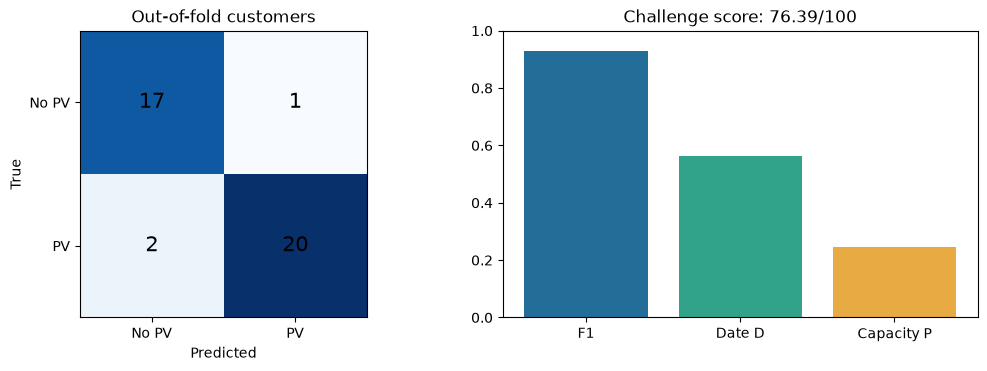

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

aligned = oof.set_index("customer_id").loc[labels.index]
cm = confusion_matrix(labels.pv_installed, aligned.pv_installed.astype(int), labels=[0, 1])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
axes[0].imshow(cm, cmap="Blues")
for (i, j), value in np.ndenumerate(cm):
    axes[0].text(j, i, str(value), ha="center", va="center", fontsize=15)
axes[0].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["No PV", "PV"],
            yticklabels=["No PV", "PV"], xlabel="Predicted", ylabel="True",
            title="Out-of-fold customers")
axes[1].bar(["F1", "Date D", "Capacity P"], [metrics["F1"], metrics["D"], metrics["P"]],
            color=["#226e99", "#31a38b", "#e8aa42"])
axes[1].set(ylim=(0, 1), title=f'Challenge score: {metrics["main_score"]:.2f}/100')
fig.savefig(ARTIFACTS / "validation.png", dpi=150)
plt.show()


## Fit the final model and package offline inference

Use all 40 development customers for the final fit. Cross-validation metrics above remain the performance estimate; predictions on these 40 training customers are **not** test performance.

The deployment module below is reconstructed from this notebook's implementation cells. Edits to those cells therefore propagate to the exported submission when this cell is rerun. No development data or labels are copied into the submission package.

Epoch 1/30: loss=3.1827


Epoch 10/30: loss=2.3716


Epoch 20/30: loss=1.6620


Epoch 30/30: loss=1.4236


Saved and verified portable model artifacts.


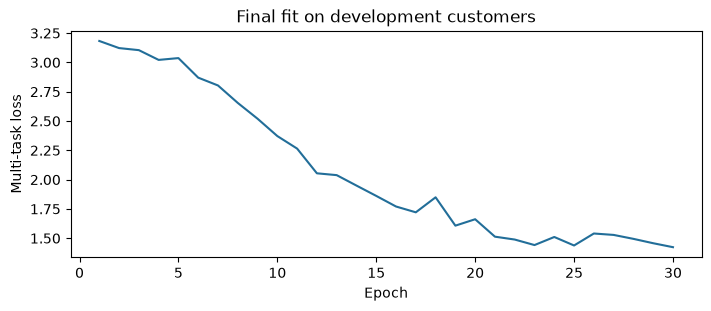

In [12]:
model, scaler, history = fit_model(series, labels, epochs=EPOCHS, seed=SEED,
                                   hidden_size=HIDDEN_SIZE, verbose=True)
save_artifact(model, scaler, ARTIFACTS / "pv_lstm.pt", threshold=THRESHOLD,
              metadata={"epochs": EPOCHS, "seed": SEED, "training_customers": len(series)})

# The authoritative implementation lives in the code cells above.
import nbformat
notebook_path = ROOT / "pv_lstm.ipynb"
nb_source = nbformat.read(notebook_path, as_version=4)
implementation_markers = ("from __future__ import annotations", "def load_series(",
    "class FeatureScaler:", "class PVLSTM(", "def fit_model(", "def save_artifact(")
implementation = [c.source for c in nb_source.cells if c.cell_type == "code" and
                  any(marker in c.source for marker in implementation_markers) and
                  "implementation_markers =" not in c.source]
assert len(implementation) == 6, "Expected six implementation cells."
for destination in [ROOT / "lstm_pipeline.py", SUBMISSION / "lstm_pipeline.py"]:
    destination.write_text("\n\n".join(implementation) + "\n", encoding="utf-8")

restored, restored_scaler, restored_threshold = load_artifact(ARTIFACTS / "pv_lstm.pt")
original = predict(model, scaler, series[:2], THRESHOLD)
reloaded = predict(restored, restored_scaler, series[:2], restored_threshold)
pd.testing.assert_frame_equal(original, reloaded)
print("Saved and verified portable model artifacts.")
fig, ax = plt.subplots(figsize=(7, 3), constrained_layout=True)
ax.plot(np.arange(1, len(history) + 1), history, color="#226e99")
ax.set(xlabel="Epoch", ylabel="Multi-task loss", title="Final fit on development customers")
fig.savefig(ARTIFACTS / "training_loss.png", dpi=150)
plt.show()


## Run on a hidden test CSV

After training, run from `lstm_submission/`:

```bash
python inference.py /absolute/path/to/test_set.csv
```

The command accepts exactly one positional argument and writes `predictions.csv` and `pv_extensions_predictions.csv` in the current working directory. It loads the checkpoint beside the script automatically and needs no network after dependency installation.

Set `TEST_CSV` below to a local test file to run inference inside this notebook. It is intentionally left unset because hidden test data was not supplied. Do not substitute the development file and report its predictions as independent evaluation.

In [13]:
TEST_CSV = None  # e.g. Path("/absolute/path/to/test_set.csv")
if TEST_CSV is not None:
    test_series, test_summary = load_series(Path(TEST_CSV))
    test_predictions = predict(restored, restored_scaler, test_series, restored_threshold)
    paths = write_outputs(test_predictions, SUBMISSION)
    print(f"Wrote both submission files for {len(test_series)} test customers.")
else:
    print("Offline inference is ready. Set TEST_CSV or use the inference.py command.")


Offline inference is ready. Set TEST_CSV or use the inference.py command.


## Limits and next experiments

- Forty independent labelled customers are a small training set for a neural network. Cross-validation can vary substantially with the customer split. Check performance against simple baselines before claiming the LSTM helps.
- Net grid withdrawal does not uniquely identify nominal kWp. Orientation, self-consumption, production, and load changes are hidden. Capacity is learned from the available labels; it is not a direct physical measurement.
- Daytime demand changes and seasonal activity can mimic PV. Dates without a visible change may be poorly estimated. This baseline restricts date predictions to observed coverage and cannot infer a commissioning date before the first observation.
- Later extensions can affect the recurrent context. The initial labels and local capacity context reduce this ambiguity but do not eliminate it. The optional extension detector is not implemented because a single development extension provides little validation evidence.
- The model uses the full history and is retrospective. Future work could use consumption-only self-supervised pretraining on the unlabelled file, additional customer-held-out evaluation, and an explicitly monotonic change-point model. Never treat unlabelled customers as negatives.

**Local source material:** `nw26_dropped_neurons-main/README.md`, `assets/knowledge/ExplorableSolutions.md`, `EnergyForDummies.md`, `AIL_NeuralWave_Challenge_EN_v1.5.pdf` (especially §§2, 4.1, 4.2, 4.4), and the development-data README. These define the challenge context; the requested architecture is the LSTM implemented here.


# Improvement study: target 95/100

The original score was **76.39/100**. This section records the actual improvement study and exports the selected pipeline. A target is not a measured result; the code below explicitly reports whether 95 was reached.

All validation customers remain excluded from their fold's training, scaler, shared factor, capacity regressors, and capacity priors. However, architectures and decoders were compared on these same development folds. The reported results are therefore **development model-selection scores**, not an unbiased hidden-test estimate. No hidden labels are available. Training-set performance is not substituted for validation.

Tested approaches include longer LSTM training; explicit local-change features; relative and teacher-forced capacity heads; robust calendar change points; shared daytime factors; nighttime and neighbour controls; hourly/censored withdrawal models; capacity regressors; and daily event ranking. Several changes performed worse and were discarded. Aggregate results are retained in `validation/experiment_results.csv`.

## Selected architecture

Use the 30-epoch LSTM for date and initial capacity, and the selected later checkpoint for presence. A robust consumption-only refiner combines the neural date, a night-adjusted local change point, and a shared daytime factor learned from training customers. Capacity combines the neural estimate, the shared factor, heavily regularized regression, and a small tree ensemble. Median aggregation limits the effect of large outliers. Capacity is then shrunk halfway toward a training-only prior that maximizes the expected capacity component. This regularization choice was compared on the development folds; it is not an independent test result.

The shared factor is learned from supplied consumption and training labels. It is not external weather or irradiation. Calendar-only extrapolation covers periods without active training installations. Extensions remain outside this baseline.


## Consumption-only refinement implementation

These are the complete definitions used in the exported module. Each fold fits them on its own training customers. Tree parameters are exported as plain tensors; inference loads both neural and refiner artifacts using `weights_only=True`.

In [14]:
"""Consumption-only refinement for the AIL multi-task LSTM.

Model parameters and a shared daytime factor are learned on training customers.
The module never reads development labels at inference.
"""
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from scipy.ndimage import gaussian_filter1d
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from lstm_pipeline import predict, load_artifact

NIGHT = [0, 1, 3, 4, 5, 22, 23]


def latent_design(s,harmonics=1,target='noon'):
    kw=np.expm1(s.x[:,:24]).astype(float)*s.scale
    day=kw[:,10:16].mean(axis=1) if target=='day' else kw[:,11:15].mean(axis=1)
    night=kw[:,NIGHT].mean(axis=1)
    phase=s.dates.dayofyear.to_numpy()/365.25*2*np.pi
    H=[np.ones(len(kw)),night/max(np.median(night),.01)]
    for h in range(1,harmonics+1): H += [np.sin(h*phase),np.cos(h*phase)]
    H += [(s.dates.dayofweek.to_numpy()==d).astype(float) for d in range(1,7)]
    return day,np.array(H).T

def learn_template(series,labels,harmonics=1,target='noon',iterations=80,smooth=0):
    dates=pd.date_range(min(s.dates[0] for s in series),max(s.dates[-1] for s in series))
    solar=np.zeros(len(dates))
    cases=[]
    for s in series:
        label=labels.loc[s.customer_id]
        if not label.pv_installed: continue
        y,H=latent_design(s,harmonics,target)
        offsets=(s.dates-dates[0]).days.to_numpy()
        active=(s.dates>=label.pv_installation_date).astype(float)
        cap=label.pv_capacity_kwp
        weight=(s.quality>.8).astype(float)
        inv=np.linalg.pinv(H.T@(weight[:,None]*H)+1e-4*np.eye(H.shape[1]))
        cases.append((y,H,offsets,active,cap,weight,inv))
    # Train-only coordinate descent for Y_i = baseline_i - capacity_i * active_i * S.
    # Calendar and contemporaneous nighttime load are the only baseline predictors.
    for _ in range(iterations):
        num=np.zeros(len(dates));den=np.zeros(len(dates))
        for y,H,ix,active,cap,weight,inv in cases:
            baseline=H@(inv@(H.T@(weight*(y+cap*active*solar[ix]))))
            residual=(baseline-y)/cap
            num[ix] += active*weight*residual
            den[ix] += active*weight
        updated=np.divide(num,den,out=np.zeros_like(num),where=den>0)
        updated=np.maximum(updated,0)
        if smooth: updated=gaussian_filter1d(updated,smooth)
        solar=.5*solar+.5*updated
    return dates,solar

def shared_candidate(s,template,harmonics=1,target='noon',min_side=7):
    dates,solar=template
    offsets=(s.dates-dates[0]).days.to_numpy()
    g=np.zeros(len(s.dates))
    covered=(offsets>=0)&(offsets<len(dates))
    g[covered]=solar[offsets[covered]]
    y,H=latent_design(s,harmonics,target)
    weight=(s.quality>.8).astype(float)
    inv=np.linalg.pinv(H.T@(weight[:,None]*H)+1e-4*np.eye(H.shape[1]))
    residual=y-H@(inv@(H.T@(weight*y)))
    suffix=lambda a:np.cumsum(a[::-1],axis=0)[::-1]
    h=suffix(weight[:,None]*g[:,None]*H)
    num=suffix(weight*g*residual)
    den=suffix(weight*g*g)-np.einsum('ij,jk,ik->i',h,inv,h)
    cap=np.maximum(-num/np.maximum(den,1e-7),.01)
    gain=np.maximum(-num,0)**2/np.maximum(den,1e-7)
    pre=np.cumsum(weight)-weight; post=suffix(weight)
    gain[(pre<min_side)|(post<min_side)]=0
    best=int(gain.argmax())
    noise=max(np.median(np.abs(residual[weight>0]-np.median(residual[weight>0])))*1.4826,.01)
    return {'offset':best,'capacity':float(cap[best]),'strength':float(np.sqrt(gain[best])/noise),
            'gain':gain,'capacities':cap}

def local_candidate(s, seasonal=.55, control='night', harmonics=1, min_side=14):
    kw=np.expm1(s.x[:,:24]).astype(float)*s.scale
    valid=s.quality>.8
    day=kw[:,10:16].mean(axis=1)
    night=kw[:,[0,1,3,4,5,22,23]].mean(axis=1)
    doy=s.dates.dayofyear.to_numpy()/365.25*2*np.pi
    # Calendar harmonic; phase is a hyperparameter, not external irradiation.
    g=1+seasonal*np.cos(doy-2*np.pi*172/365.25)
    controls=[np.ones(len(kw))]
    if control in ['night','difference','ratio']:
        controls += [night/max(np.median(night),.01)]
    if control=='difference': day=day-night
    if control=='ratio': day=day/np.maximum(night,s.scale*.1)
    for h in range(1,harmonics+1):
        controls += [np.sin(doy*h),np.cos(doy*h)]
    controls += [(s.dates.dayofweek.to_numpy()==d).astype(float) for d in range(1,7)]
    H=np.array(controls).T
    weight=valid.astype(float)
    scale=max(np.median(day),.01)
    day=day/scale
    # Robustly suppress isolated outages/holiday spikes without erasing steps.
    for _ in range(3):
        inv=np.linalg.pinv(H.T@(weight[:,None]*H)+1e-5*np.eye(H.shape[1]))
        beta=inv@(H.T@(weight*day))
        residual=day-H@beta
        mad=max(np.median(np.abs(residual[valid]-np.median(residual[valid])))*1.4826,.01)
        weight=valid*np.minimum(1,2.5*mad/np.maximum(np.abs(residual),1e-8))
    inv=np.linalg.pinv(H.T@(weight[:,None]*H)+1e-5*np.eye(H.shape[1]))
    residual=day-H@(inv@(H.T@(weight*day)))
    suffix=lambda a: np.cumsum(a[::-1],axis=0)[::-1]
    h=suffix(weight[:,None]*g[:,None]*H)
    numerator=suffix(weight*g*residual)
    denominator=suffix(weight*g*g)-np.einsum('ij,jk,ik->i',h,inv,h)
    amplitude=-numerator/np.maximum(denominator,1e-6)
    gain=np.maximum(-numerator,0)**2/np.maximum(denominator,1e-6)
    pre=np.cumsum(valid)-valid
    post=suffix(valid)
    gain[(pre<min_side)|(post<min_side)]=0
    if gain.max()<=0: best=0
    else: best=int(np.argmax(gain))
    noise=max(np.median(np.abs(residual[valid]-np.median(residual[valid])))*1.4826,.01)
    return {'offset':best,'amplitude':float(max(amplitude[best]*scale,0)),
            'strength':float(np.sqrt(gain[best])/noise),'gain':gain,'amplitudes':amplitude*scale,
            'noise':noise*scale}

def capacity_features(s,offset):
    raw=np.expm1(s.x[:,:24]).astype(float)*s.scale
    n=len(raw);d=int(np.clip(offset,0,n-1))
    before=raw[max(0,d-365):max(d,1)]
    after=raw[d:min(n,d+180)]
    nearbefore=raw[max(0,d-60):max(d,1)]
    nearafter=raw[d:min(n,d+60)]
    phase=s.dates[d].dayofyear/365.25*2*np.pi
    values=[np.log1p(s.scale),np.sin(phase),np.cos(phase),min(d,365)/365,min(n-d,365)/365]
    for data in [before,after,nearbefore,nearafter]:
        for hours in [slice(10,16),slice(11,15),[0,1,3,4,5,22,23],slice(6,10),slice(16,20)]:
            x=data[:,hours].mean(axis=1)
            values.extend(np.log1p(np.quantile(x,[.05,.25,.5,.75,.95])))
        values.extend((data[:,9:17]<s.scale*.05).mean(axis=0))
    for a,b in [(before,after),(nearbefore,nearafter)]:
        diff=np.median(a,axis=0)-np.median(b,axis=0)
        values.extend(np.arcsinh(diff/s.scale))
    y,H=latent_design(s,harmonics=2,target='noon')
    valid=(s.quality>.8)&(np.arange(n)<d)
    if valid.sum()>=14:
        ridge=np.eye(H.shape[1])*.01
        beta=np.linalg.solve(H[valid].T@H[valid]+ridge,H[valid].T@y[valid])
        residual=(H@beta-y)[d:min(n,d+180)]
        values.extend(np.arcsinh(np.quantile(residual,[.1,.25,.5,.75,.9,.95,.99])/s.scale))
        values.extend([np.log1p(max(np.quantile(residual,q),0)) for q in [.5,.75,.9,.95,.99]])
    else: values.extend([0.]*12)
    values.extend(np.log1p(np.quantile(raw[:,11:15].mean(1),[.05,.25,.5,.75,.95])))
    return np.nan_to_num(values).astype(float)



def fit_refiner(series, labels):
    """Fit only on the supplied training-customer labels and consumption."""
    template = learn_template(series, labels, harmonics=2, target='noon')
    grid, solar = template
    available = np.zeros(len(grid), dtype=bool)
    positives = []
    for s in series:
        label = labels.loc[s.customer_id]
        if not label.pv_installed:
            continue
        positives.append(s)
        ix = (s.dates - grid[0]).days.to_numpy()
        available[ix[s.dates >= label.pv_installation_date]] = True
    if not positives or not available.any():
        raise ValueError('The refiner requires PV-positive training customers.')
    # Calendar extrapolation covers days with no active training installation.
    phase = grid.dayofyear.to_numpy() / 365.25 * 2 * np.pi
    H = np.column_stack([np.ones(len(grid)), np.sin(phase), np.cos(phase),
                         np.sin(2 * phase), np.cos(2 * phase)])
    calendar_coef = np.linalg.lstsq(H[available], solar[available], rcond=None)[0]
    solar = np.where(available, solar, np.maximum(H @ calendar_coef, 0))
    X = np.stack([capacity_features(s, (labels.loc[s.customer_id, 'pv_installation_date'] - s.dates[0]).days)
                  for s in positives])
    target = np.log([labels.loc[s.customer_id, 'pv_capacity_kwp'] for s in positives])
    capacities = np.exp(target)
    expected_p = np.maximum(0, 1-2*np.abs(capacities[:, None]-capacities[None, :])
                            / capacities[:, None]).mean(axis=0)
    capacity_prior = float(capacities[expected_p.argmax()])
    ridge = make_pipeline(StandardScaler(), Ridge(alpha=1000)).fit(X, target)
    forest = ExtraTreesRegressor(n_estimators=200, min_samples_leaf=2, max_features=.7,
                                 random_state=42, n_jobs=2).fit(X, target)
    trees = []
    for estimator in forest.estimators_:
        t = estimator.tree_
        trees.append({'left': t.children_left.copy(), 'right': t.children_right.copy(),
                      'feature': t.feature.copy(), 'threshold': t.threshold.copy(),
                      'value': t.value[:, 0, 0].copy()})
    result = {'template_start': grid[0].strftime('%Y-%m-%d'), 'solar': solar,
              'calendar_coef': calendar_coef, 'ridge_mean': ridge[0].mean_,
              'ridge_scale': ridge[0].scale_, 'ridge_coef': ridge[1].coef_,
              'ridge_intercept': float(ridge[1].intercept_), 'trees': trees,
              'capacity_prior': capacity_prior, 'capacity_shrinkage': 0.5}
    # Verify our small dependency-independent tree evaluator before export.
    reference = forest.predict(X)
    restored = np.array([_forest_predict(row, trees) for row in X])
    np.testing.assert_allclose(reference, restored, rtol=1e-7, atol=1e-7)
    return result


def _forest_predict(x, trees):
    # sklearn tree input is float32; match its threshold comparisons exactly.
    x = np.asarray(x, dtype=np.float32)
    values = []
    for t in trees:
        node = 0
        while t['left'][node] >= 0:
            node = int(t['left'][node] if x[int(t['feature'][node])] <= t['threshold'][node]
                       else t['right'][node])
        values.append(t['value'][node])
    return float(np.mean(values))


def refine_predictions(series, base, refiner):
    result = base.copy().set_index('customer_id')
    grid = pd.date_range(refiner['template_start'], periods=len(refiner['solar']))
    template = (grid, refiner['solar'])
    for s in series:
        cid = s.customer_id
        if not bool(result.loc[cid, 'pv_installed']):
            result.loc[cid, 'pv_installation_date'] = ''
            result.loc[cid, 'pv_capacity_kwp'] = np.nan
            continue
        shared = shared_candidate(s, template, harmonics=2, target='noon')
        local = local_candidate(s, seasonal=.55, control='ratio', harmonics=0, min_side=7)
        base_date = pd.Timestamp(result.loc[cid, 'pv_installation_date'])
        offsets = [(base_date-s.dates[0]).days, shared['offset'], local['offset']]
        date = int(np.clip(np.median(offsets), 0, len(s.dates)-1))
        # Capacity uses the shared-factor event; date consensus has its own decoder.
        x = capacity_features(s, shared['offset'])
        normalized = (x-refiner['ridge_mean']) / refiner['ridge_scale']
        ridge_log = float(normalized @ refiner['ridge_coef'] + refiner['ridge_intercept'])
        forest_log = _forest_predict(x, refiner['trees'])
        capacities = [float(result.loc[cid, 'pv_capacity_kwp']), shared['capacity'],
                      np.exp(np.clip(ridge_log, -3, 12)), np.exp(np.clip(forest_log, -3, 12))]
        capacities = [c for c in capacities if np.isfinite(c) and c > 0]
        result.loc[cid, 'pv_installation_date'] = s.dates[date].strftime('%Y-%m-%d')
        estimate_log = float(np.median(np.log(capacities)))
        shrink = float(refiner.get('capacity_shrinkage', 0.))
        if shrink:
            estimate_log = (1-shrink)*estimate_log + shrink*np.log(refiner['capacity_prior'])
        result.loc[cid, 'pv_capacity_kwp'] = float(np.exp(estimate_log))
    return result.reset_index()


def predict_refined(model, scaler, series, refiner, threshold=.5):
    return refine_predictions(series, predict(model, scaler, series, threshold), refiner)


def save_refiner(refiner, path):
    def tensors(obj):
        if isinstance(obj, np.ndarray): return torch.from_numpy(obj.copy())
        if isinstance(obj, dict): return {k: tensors(v) for k, v in obj.items()}
        if isinstance(obj, list): return [tensors(v) for v in obj]
        return obj
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save({'format_version': 1, 'parameters': tensors(refiner)}, path)


def load_refiner(path):
    def arrays(obj):
        if torch.is_tensor(obj): return obj.numpy()
        if isinstance(obj, dict): return {k: arrays(v) for k, v in obj.items()}
        if isinstance(obj, list): return [arrays(v) for v in obj]
        return obj
    artifact = torch.load(path, map_location='cpu', weights_only=True)
    if artifact['format_version'] != 1: raise ValueError('Unsupported refiner artifact version.')
    return arrays(artifact['parameters'])


def predict_bundle(artifact_dir, series):
    """Offline inference with separate presence and event checkpoints."""
    artifact_dir = Path(artifact_dir)
    model, scaler, _ = load_artifact(artifact_dir/'pv_lstm.pt')
    presence, presence_scaler, threshold = load_artifact(artifact_dir/'pv_presence.pt')
    base = predict(model, scaler, series, threshold=0.)
    classification = predict(presence, presence_scaler, series, threshold).set_index('customer_id')
    base['pv_installed'] = base.customer_id.map(classification.pv_installed)
    base['pv_probability'] = base.customer_id.map(classification.pv_probability)
    return refine_predictions(series, base, load_refiner(artifact_dir/'pv_refiner.pt'))


In [15]:
# Export the displayed improvement implementations before importing them.
# This makes edits to these notebook cells propagate to training and inference.
import nbformat
from pathlib import Path
source_root = Path.cwd()
if not (source_root / "pv_lstm.ipynb").exists():
    source_root = source_root.parent
current_nb = nbformat.read(source_root / "pv_lstm.ipynb", as_version=4)
for filename, marker in [("pv_refinement.py", '"""Consumption-only refinement for the AIL'),
                         ("pv_training.py", '"""Reproducible training and customer-fold')]:
    sources = [c.source for c in current_nb.cells if c.cell_type == "code" and c.source.startswith(marker)]
    assert len(sources) == 1
    (source_root / filename).write_text(sources[0] + "\n", encoding="utf-8")


## Training and validation implementation

Checkpoint evaluation uses customer inputs only; validation labels are used solely for scoring. Epoch counts and pipeline structure are selected through the development study and must be fixed before any future hidden-test evaluation.

In [16]:
"""Reproducible training and customer-fold validation of the improved pipeline."""
import copy
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader
from sklearn.model_selection import StratifiedKFold
from lstm_pipeline import (PVLSTM, FeatureScaler, CustomerDataset, collate,
                           seed_everything, multitask_loss, predict, challenge_metrics,
                           save_artifact)
from pv_refinement import fit_refiner, refine_predictions, save_refiner


def fit_checkpoints(series, labels, epochs=60, seed=42, evaluation_series=None, verbose=False):
    """Keep the 30-epoch date/capacity head and later presence head.

    All epochs and decoder choices are fixed before a fold is fitted. Intermediate
    evaluation uses INPUTS only, never validation labels or early stopping.
    """
    if epochs < 30 or epochs % 30:
        raise ValueError('epochs must be a positive multiple of 30, at least 30.')
    seed_everything(seed)
    scaler = FeatureScaler().fit(series)
    subset = labels.loc[[s.customer_id for s in series]]
    loader = DataLoader(CustomerDataset(series, scaler, subset), batch_size=8, shuffle=True,
                        collate_fn=collate, generator=torch.Generator().manual_seed(seed))
    model = PVLSTM(series[0].x.shape[1], 24)
    y = subset.pv_installed.to_numpy()
    weight = torch.tensor((len(y)-y.sum())/max(y.sum(), 1))
    prior = float(np.log1p(subset.query('pv_installed==1').pv_capacity_kwp).mean())
    nn.init.constant_(model.capacity_head[-1].bias, prior)
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-3)
    snapshots, predictions, history = {}, {}, []
    evaluation_series = series if evaluation_series is None else evaluation_series
    for epoch in range(1, epochs+1):
        model.train()
        losses = []
        for batch in loader:
            optimizer.zero_grad(set_to_none=True)
            out = model(batch['x'], batch['lengths'], batch['mask'])
            loss = multitask_loss(out, batch, weight)
            if not torch.isfinite(loss):
                raise FloatingPointError('Nonfinite training loss.')
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.)
            optimizer.step()
            losses.append(float(loss.detach()))
        history.append(float(np.mean(losses)))
        if epoch % 30 == 0:
            snapshots[epoch] = copy.deepcopy(model).cpu().eval()
            # A single inference pass per checkpoint keeps this training schedule
            # identical to the measured trajectory experiment.
            predictions[epoch] = predict(model, scaler, evaluation_series,
                                         threshold=0. if epoch == 30 else .5)
        if verbose and (epoch == 1 or epoch % 10 == 0):
            print(f'Improved fit epoch {epoch}/{epochs}: loss={history[-1]:.4f}', flush=True)
    return snapshots, scaler, predictions, history


def cross_validate_refined(series, labels, epochs=60, folds=5, seed=42):
    ids = [s.customer_id for s in series]
    y = labels.loc[ids].pv_installed.to_numpy(int)
    oof, metrics = [], []
    split = StratifiedKFold(folds, shuffle=True, random_state=seed)
    for fold, (tr, va) in enumerate(split.split(ids, y), 1):
        training = [series[i] for i in tr]
        validation = [series[i] for i in va]
        subset = labels.loc[[s.customer_id for s in training]]
        models, scaler, predictions, _ = fit_checkpoints(training, subset, epochs,
                                                         seed+fold, validation)
        base = predictions[30].copy()
        presence = predictions[epochs]
        if epochs == 30:
            base['pv_installed'] = base.pv_probability >= .5
        else:
            base['pv_installed'] = presence.pv_installed.to_numpy()
            base['pv_probability'] = presence.pv_probability.to_numpy()
        refiner = fit_refiner(training, subset)
        prediction = refine_predictions(validation, base, refiner)
        prediction['fold'] = fold
        score = challenge_metrics(labels.loc[[s.customer_id for s in validation]], prediction)
        oof.append(prediction)
        metrics.append({'fold': fold, **score})
        print(f'Refined fold {fold}/{folds}: F1={score["F1"]:.3f}, score={score["main_score"]:.2f}', flush=True)
    return pd.concat(oof, ignore_index=True), pd.DataFrame(metrics)


def fit_final_refined(series, labels, artifact_dir, epochs=60, seed=42):
    artifact_dir = Path(artifact_dir)
    artifact_dir.mkdir(parents=True, exist_ok=True)
    models, scaler, _, history = fit_checkpoints(series, labels, epochs, seed, verbose=True)
    save_artifact(models[30], scaler, artifact_dir/'pv_lstm.pt',
                  metadata={'epochs': 30, 'seed': seed, 'role': 'date_and_capacity'})
    save_artifact(models[epochs], scaler, artifact_dir/'pv_presence.pt',
                  metadata={'epochs': epochs, 'seed': seed, 'role': 'presence'})
    refiner = fit_refiner(series, labels)
    save_refiner(refiner, artifact_dir/'pv_refiner.pt')
    return history


## Load the verified validation run or recompute it

The default uses the measured run saved with this notebook, checking input and implementation fingerprints first. Set `RECOMPUTE_STUDY=True` to retrain all five folds. This can take several minutes. Recomputing uses the same checkpoint schedule as the measured experiment. No customer rows are printed.

In [17]:
import hashlib, ast, json, nbformat
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lstm_pipeline import load_series, read_labels, challenge_metrics, load_artifact, write_outputs

ROOT = Path.cwd()
if not (ROOT / "AIL_data_for_neural_wave_v1.1").exists() and (ROOT.parent / "AIL_data_for_neural_wave_v1.1").exists():
    ROOT = ROOT.parent
DATA = ROOT / "AIL_data_for_neural_wave_v1.1" / "challenge_set"
SUBMISSION = ROOT / "lstm_submission"
ARTIFACTS = SUBMISSION / "artifacts"
VALIDATION = ROOT / "validation"
IMPROVED_PRESENCE_EPOCHS = 60
RECOMPUTE_STUDY = False
RETRAIN_FINAL = False
TARGET_SCORE = 95.0

series, _ = load_series(DATA / "energy_consumption_dev.csv")
labels = read_labels(DATA / "pv_labels_dev.csv")

def study_fingerprints():
    hashes = {}
    for path in [DATA / "energy_consumption_dev.csv", DATA / "pv_labels_dev.csv",
                 ROOT / "lstm_pipeline.py", ROOT / "pv_refinement.py", ROOT / "pv_training.py"]:
        if path.suffix == ".py":
            payload = ast.dump(ast.parse(path.read_text()), include_attributes=False).encode()
            hashes[path.name] = hashlib.sha256(payload).hexdigest()
        else:
            digest = hashlib.sha256()
            with path.open("rb") as stream:
                for chunk in iter(lambda: stream.read(1024 * 1024), b""):
                    digest.update(chunk)
            hashes[path.name] = digest.hexdigest()
    return hashes

if RECOMPUTE_STUDY:
    improved_oof, improved_folds = cross_validate_refined(series, labels, epochs=IMPROVED_PRESENCE_EPOCHS)
    improved_oof.to_csv(VALIDATION / "improved_oof.csv", sep=";", index=False)
    improved_folds.to_csv(VALIDATION / "improved_folds.csv", sep=";", index=False)
    cache_meta = {"fingerprints": study_fingerprints(), "presence_epochs": IMPROVED_PRESENCE_EPOCHS,
                  "date_capacity_epochs": 30, "folds": 5, "seed": 42,
                  "evaluation": "development model selection; not hidden-test performance"}
    (VALIDATION / "cache_manifest.json").write_text(json.dumps(cache_meta, indent=2))
else:
    cache_meta = json.loads((VALIDATION / "cache_manifest.json").read_text())
    assert cache_meta["fingerprints"] == study_fingerprints(), "Source/data changed: set RECOMPUTE_STUDY=True."
    assert cache_meta["presence_epochs"] == IMPROVED_PRESENCE_EPOCHS
    improved_oof = pd.read_csv(VALIDATION / "improved_oof.csv", sep=";", dtype={"customer_id":str})
    improved_folds = pd.read_csv(VALIDATION / "improved_folds.csv", sep=";")
assert set(improved_oof.customer_id) == set(labels.index)
assert len(improved_oof) == len(labels)
improved_metrics = challenge_metrics(labels, improved_oof)
print("Selected pipeline development cross-validation:")
print(json.dumps(improved_metrics, indent=2))
print(f"95/100 target: {'REACHED' if improved_metrics['main_score'] >= TARGET_SCORE else 'NOT REACHED'}")
print(f"Improvement over original: {improved_metrics['main_score'] - 76.3933942794709:.2f} points")


Selected pipeline development cross-validation:
{
  "F1": 0.9767441860465116,
  "precision": 1.0,
  "recall": 0.9545454545454546,
  "D": 0.7634920634920634,
  "P": 0.42677673352679024,
  "main_score": 85.81091493306693,
  "true_positives": 21,
  "date_MAE_days_on_true_positives": 19.571428571428573,
  "capacity_MAPE_on_true_positives": 0.6946441577304509
}
95/100 target: NOT REACHED
Improvement over original: 9.42 points


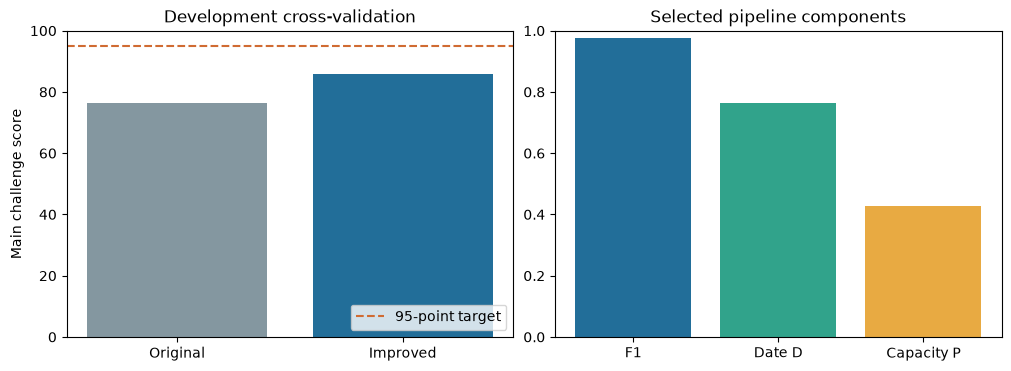

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
axes[0].bar(["Original", "Improved"], [76.3933942794709, improved_metrics["main_score"]],
            color=["#8497a0", "#226e99"])
axes[0].axhline(TARGET_SCORE, color="#d06b32", linestyle="--", label="95-point target")
axes[0].set(ylim=(0, 100), ylabel="Main challenge score", title="Development cross-validation")
axes[0].legend(loc="lower right")
axes[1].bar(["F1", "Date D", "Capacity P"],
            [improved_metrics["F1"], improved_metrics["D"], improved_metrics["P"]],
            color=["#226e99", "#31a38b", "#e8aa42"])
axes[1].set(ylim=(0, 1), title="Selected pipeline components")
fig.savefig(ARTIFACTS / "improvement.png", dpi=150)
plt.show()


## Export the selected model and verify offline inference

Trained artifacts from the executed study are included. Set `RETRAIN_FINAL=True` to recreate them from all 40 development customers. This does not change the reported validation results. The exported command accepts exactly one input CSV and writes both required semicolon-separated files.

Only aggregate results, code and model parameters belong in a shared submission. Local out-of-fold diagnostics contain customer IDs and should stay local.

In [19]:
import shutil, zipfile

ARTIFACTS.mkdir(parents=True, exist_ok=True)
if RETRAIN_FINAL:
    improved_history = fit_final_refined(series, labels, ARTIFACTS,
                                        epochs=IMPROVED_PRESENCE_EPOCHS, seed=42)
else:
    for name in ["pv_lstm.pt", "pv_presence.pt", "pv_refiner.pt"]:
        assert (ARTIFACTS / name).exists(), f"Missing {name}: set RETRAIN_FINAL=True."

# Export the exact refinement definitions displayed in this notebook.
nb_current = nbformat.read(ROOT / "pv_lstm.ipynb", as_version=4)
refinement_cells = [c.source for c in nb_current.cells if c.cell_type == "code"
                    and c.source.startswith('"""Consumption-only refinement for the AIL')]
assert len(refinement_cells) == 1
(ROOT / "pv_refinement.py").write_text(refinement_cells[0] + "\n", encoding="utf-8")
shutil.copyfile(ROOT / "pv_refinement.py", SUBMISSION / "pv_refinement.py")

# Repeated single-customer inference confirms no dependence on test neighbours.
whole = predict_bundle(ARTIFACTS, series[:2])
one = predict_bundle(ARTIFACTS, series[:1])
pd.testing.assert_frame_equal(whole.iloc[:1].reset_index(drop=True), one)
assert set(whole.customer_id) == {s.customer_id for s in series[:2]}
print("Verified trained bundle and customer-independent inference.")

submission_files = ["inference.py", "lstm_pipeline.py", "pv_refinement.py", "requirements.txt", "README.md",
                    "artifacts/pv_lstm.pt", "artifacts/pv_presence.pt", "artifacts/pv_refiner.pt"]
with zipfile.ZipFile(ROOT / "lstm_submission.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for name in submission_files:
        archive.write(SUBMISSION / name, arcname="lstm_submission/" + name)
print("Saved the offline submission package with code and three trained artifacts.")


# Latest in-notebook inference uses the selected improved bundle.
if globals().get("TEST_CSV") is not None:
    final_test_series, _ = load_series(Path(TEST_CSV))
    final_predictions = predict_bundle(ARTIFACTS, final_test_series)
    write_outputs(final_predictions, SUBMISSION)
    print(f"Updated both output files with the improved model for {len(final_predictions)} customers.")


Verified trained bundle and customer-independent inference.
Saved the offline submission package with code and three trained artifacts.


## Remaining gap to 95

The exact measured result and target status are printed above. F1, commissioning accuracy, and capacity accuracy all contribute to the main score. Strong detection alone cannot deliver 95 when nominal-capacity estimates remain uncertain.

No training-set score, optional-extension bonus, hidden-label access, customer-ID feature, or memorized customer lookup is used to claim success. Development-fold tuning can overestimate generalization; the organizer's hidden test remains the final check. More labelled diversity and carefully validated consumption-only pretraining are possible next experiments, with no guarantee of reaching 95.